# Assignment : Face Authentication Under Presentation and Adversarial Attacks

## Problem and goal
A face authentication system should accept a live person and reject a presentation attack such as a printed photo or a replayed image. This notebook builds a beginner-sized presentation-attack detector with two labels: **Live** and **Spoof**.

## Solution and approach
The CNN is trained on the labeled OULU images. The subject ID in each filename keeps a person's images together when the data is split, so validation subjects are not used for training. Images are resized to 128 x 128, mildly augmented during training, and sampled with partial class balancing. The model is tested on labeled CASIA-FASD and CelebA-Spoof images, then clean results are compared with FGSM adversarial results.

## Important data limitation
The local Replay-Mobile folder has 39 MP4 files organized by device pair, but no live/spoof labels. It cannot produce a scored validation result. This run therefore uses the labeled OULU subject holdout for validation and states that deviation openly.

## What the run shows
In the recorded Version 2 run, OULU validation was 98.2% accurate, but that same holdout was used to choose the best epoch. The clean balanced accuracy was only 51.8% on CASIA and 58.2% on CelebA-Spoof. Under FGSM, accuracy fell to 10.4% on CASIA and 3.7% on CelebA-Spoof. The code and evaluation pipeline completed, but these cross-dataset and adversarial results show that the model is **not yet a reliable or robust detector**.


## How to use this notebook

Run the cells from top to bottom. The notebook prints the data split, training progress, and a clear completion message; it then displays annotated confusion matrices and a formatted metric table. It saves the model, metrics CSV, and figures under `outputs_v3`. The training architecture and data protocol match Version 2 so the presentation changes do not change the experiment.


In [1]:
from pathlib import Path
import csv
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from PIL import Image, ImageEnhance, ImageOps
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay


## 1. Data paths and experiment settings

The raw datasets stay on disk and are read in batches. Change `PROJECT_DIR` if the assignment folder is moved. Version 3 writes outputs to its own folder and does not overwrite the Version 2 run.


In [2]:
PROJECT_DIR = Path(r'C:\Users\krish\Desktop\Study Material\SEM-7\Biometric\p\assignment39')
RAW_DIR = PROJECT_DIR / 'data' / 'raw'
OULU_DIR = RAW_DIR / 'Oulu-NPU'
CASIA_DIR = RAW_DIR / 'casia-fasd'
CELEBA_DIR = RAW_DIR / 'CelebA_Spoof_' / 'CelebA_Spoof'
OUTPUT_DIR = PROJECT_DIR / 'outputs_v3'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
IMAGE_SIZE = 128
BATCH_SIZE = 16
EPOCHS = 20
LEARNING_RATE = 0.0005
FGSM_EPSILON = 8 / 255
CELEBA_PER_CLASS = 1000

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    DEVICE = torch.device('cuda')
else:
    DEVICE = torch.device('cpu')
pin_memory = DEVICE.type == 'cuda'


## 2. Read the OULU labels and make a subject split

The `true` folder supplies live labels (`0`) and the `false` folder supplies spoof labels (`1`). The third underscore-separated filename field is the subject ID. We hold out four of the 20 subjects, using a fixed seed, and keep all images from each subject on one side of the split. The counts below show the data actually used. This local copy has no official protocol split files.


In [3]:
def image_files(folder, extensions={'.jpg', '.jpeg', '.png'}):
    return sorted(p for p in folder.iterdir() if p.is_file() and p.suffix.lower() in extensions)

oulu_records = []
for label, class_folder in [(0, 'true'), (1, 'false')]:
    for path in image_files(OULU_DIR / class_folder):
        subject_id = path.stem.split('_')[2]
        oulu_records.append({'path': path, 'label': label, 'group': subject_id})

oulu_counts = {name: sum(r['label'] == label for r in oulu_records)
               for label, name in [(0, 'live'), (1, 'spoof')]}
subject_ids = sorted({r['group'] for r in oulu_records}, key=int)
split_rng = random.Random(SEED)
val_subjects = set(split_rng.sample(subject_ids, k=max(1, round(0.20 * len(subject_ids)))))
train_records = [r for r in oulu_records if r['group'] not in val_subjects]
val_records = [r for r in oulu_records if r['group'] in val_subjects]
train_subjects = {r['group'] for r in train_records}

print('DATA SPLIT READY')
print(f'OULU: {len(oulu_records):,} labeled images | {oulu_counts["live"]:,} live | {oulu_counts["spoof"]:,} spoof')
print(f'Train: {len(train_records):,} images from {len(train_subjects)} subjects')
print(f'Validation: {len(val_records):,} images from {len(val_subjects)} held-out subjects')
print('Train class counts:', {name: sum(r['label'] == label for r in train_records)
                              for label, name in [(0, 'live'), (1, 'spoof')]})
print('Validation class counts:', {name: sum(r['label'] == label for r in val_records)
                                   for label, name in [(0, 'live'), (1, 'spoof')]})


DATA SPLIT READY
OULU: 1,701 labeled images | 343 live | 1,358 spoof
Train: 1,361 images from 16 subjects
Validation: 340 images from 4 held-out subjects
Train class counts: {'live': 276, 'spoof': 1085}
Validation class counts: {'live': 67, 'spoof': 273}


## 3. Preprocess images and balance training samples

Every image is resized to 128 x 128 and scaled to the 0–1 range. Training uses random horizontal flips and small brightness/contrast changes. Validation and test images are not augmented. A square-root sampler partly offsets the live/spoof imbalance without forcing a 50/50 training mix.


In [4]:
class FaceImageDataset(Dataset):
    def __init__(self, records, image_size=IMAGE_SIZE, augment=False):
        self.records = records
        self.image_size = image_size
        self.augment = augment

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        record = self.records[index]
        with Image.open(record['path']) as source:
            image = source.convert('RGB').resize((self.image_size, self.image_size), Image.Resampling.BILINEAR)
        if self.augment:
            if random.random() < 0.5:
                image = ImageOps.mirror(image)
            image = ImageEnhance.Brightness(image).enhance(random.uniform(0.9, 1.1))
            image = ImageEnhance.Contrast(image).enhance(random.uniform(0.9, 1.1))
        array = np.asarray(image, dtype=np.float32).copy() / 255.0
        tensor = torch.from_numpy(array).permute(2, 0, 1)
        label = torch.tensor(record['label'], dtype=torch.long)
        return tensor, label

train_counts = np.bincount([r['label'] for r in train_records], minlength=2)
# Square-root weights partly offset the imbalance without forcing a 50/50 training mix.
sample_weights = torch.DoubleTensor([1.0 / np.sqrt(train_counts[r['label']]) for r in train_records])
sampler_generator = torch.Generator().manual_seed(SEED)
train_sampler = WeightedRandomSampler(sample_weights, num_samples=len(train_records),
                                      replacement=True, generator=sampler_generator)
train_loader = DataLoader(FaceImageDataset(train_records, augment=True), batch_size=BATCH_SIZE,
                          sampler=train_sampler, num_workers=0, pin_memory=pin_memory)
val_loader = DataLoader(FaceImageDataset(val_records), batch_size=BATCH_SIZE,
                        shuffle=False, num_workers=0, pin_memory=pin_memory)


## 4. CNN architecture and training

The CNN uses three convolution blocks with 24, 48, and 96 channels. Each block has two convolutions, batch normalization, and max pooling. A 4×4 average-pooled feature map keeps some spatial texture information; a 64-unit layer and dropout produce the final Live/Spoof scores. Training uses AdamW, cross-entropy loss, batch size 16, 20 epochs, and learning rate 0.0005. The saved checkpoint is the epoch with the best OULU validation balanced accuracy.


In [5]:
class SmallPADCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 24, kernel_size=3, padding=1),
            nn.BatchNorm2d(24), nn.ReLU(),
            nn.Conv2d(24, 24, kernel_size=3, padding=1),
            nn.BatchNorm2d(24), nn.ReLU(), nn.MaxPool2d(2),

            nn.Conv2d(24, 48, kernel_size=3, padding=1),
            nn.BatchNorm2d(48), nn.ReLU(),
            nn.Conv2d(48, 48, kernel_size=3, padding=1),
            nn.BatchNorm2d(48), nn.ReLU(), nn.MaxPool2d(2),

            nn.Conv2d(48, 96, kernel_size=3, padding=1),
            nn.BatchNorm2d(96), nn.ReLU(),
            nn.Conv2d(96, 96, kernel_size=3, padding=1),
            nn.BatchNorm2d(96), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((4, 4)), nn.Flatten()
        )
        self.classifier = nn.Sequential(
            nn.Linear(96 * 4 * 4, 64), nn.ReLU(), nn.Dropout(0.4), nn.Linear(64, 2)
        )

    def forward(self, images):
        return self.classifier(self.features(images))

model = SmallPADCNN().to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)

history = {'train_loss': [], 'validation_accuracy': [], 'validation_balanced_accuracy': []}
best_validation_score = -1.0
best_epoch = 0
best_weights = None

print('MODEL TRAINING STARTED')
print(f'Using {len(train_records):,} OULU training images | {IMAGE_SIZE}x{IMAGE_SIZE} | batch {BATCH_SIZE} | {EPOCHS} epochs')

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0
    seen = 0
    for images, labels in train_loader:
        images = images.to(DEVICE, non_blocking=pin_memory)
        labels = labels.to(DEVICE, non_blocking=pin_memory)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(images), labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * labels.size(0)
        seen += labels.size(0)

    model.eval()
    val_true, val_pred = [], []
    with torch.no_grad():
        for images, labels in val_loader:
            logits = model(images.to(DEVICE, non_blocking=pin_memory))
            val_pred.extend(logits.argmax(dim=1).cpu().tolist())
            val_true.extend(labels.tolist())

    epoch_loss = total_loss / seen
    epoch_accuracy = accuracy_score(val_true, val_pred)
    epoch_balanced_accuracy = balanced_accuracy_score(val_true, val_pred)
    history['train_loss'].append(epoch_loss)
    history['validation_accuracy'].append(epoch_accuracy)
    history['validation_balanced_accuracy'].append(epoch_balanced_accuracy)

    if epoch_balanced_accuracy > best_validation_score:
        best_validation_score = epoch_balanced_accuracy
        best_epoch = epoch + 1
        best_weights = {name: value.detach().cpu().clone()
                        for name, value in model.state_dict().items()}

    print(f'Epoch {epoch + 1:02d}/{EPOCHS} | loss {epoch_loss:.4f} | '
          f'accuracy {epoch_accuracy:.3f} | balanced accuracy {epoch_balanced_accuracy:.3f}')

model.load_state_dict(best_weights)
model_path = OUTPUT_DIR / 'pad_cnn_v3_state_dict.pt'
torch.save(model.state_dict(), model_path)
print('MODEL TRAINED')
print(f'Best checkpoint: epoch {best_epoch} | validation balanced accuracy {best_validation_score:.1%}')
print(f'Model saved to: {model_path}')


MODEL TRAINING STARTED
Using 1,361 OULU training images | 128x128 | batch 16 | 20 epochs
Epoch 01/20 | loss 0.4837 | accuracy 0.879 | balanced accuracy 0.835
Epoch 02/20 | loss 0.3252 | accuracy 0.909 | balanced accuracy 0.887
Epoch 03/20 | loss 0.3159 | accuracy 0.900 | balanced accuracy 0.836
Epoch 04/20 | loss 0.1771 | accuracy 0.950 | balanced accuracy 0.941
Epoch 05/20 | loss 0.1413 | accuracy 0.903 | balanced accuracy 0.821
Epoch 06/20 | loss 0.3603 | accuracy 0.947 | balanced accuracy 0.899
Epoch 07/20 | loss 0.1619 | accuracy 0.935 | balanced accuracy 0.948
Epoch 08/20 | loss 0.1466 | accuracy 0.941 | balanced accuracy 0.913
Epoch 09/20 | loss 0.1294 | accuracy 0.965 | balanced accuracy 0.922
Epoch 10/20 | loss 0.1156 | accuracy 0.953 | balanced accuracy 0.892
Epoch 11/20 | loss 0.1327 | accuracy 0.950 | balanced accuracy 0.952
Epoch 12/20 | loss 0.0873 | accuracy 0.915 | balanced accuracy 0.806
Epoch 13/20 | loss 0.3403 | accuracy 0.974 | balanced accuracy 0.967
Epoch 14/20 | 

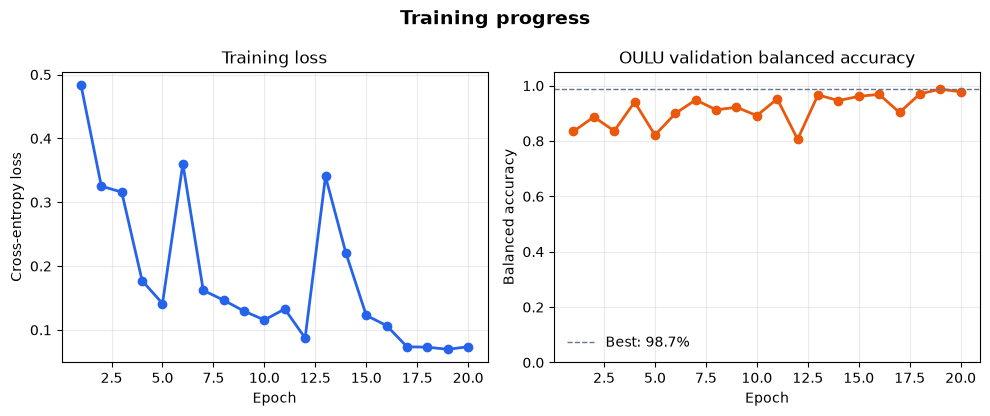

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
epoch_numbers = range(1, EPOCHS + 1)
axes[0].plot(epoch_numbers, history['train_loss'], color='#2563eb', marker='o', linewidth=2)
axes[0].set_title('Training loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cross-entropy loss')
axes[0].grid(True, alpha=0.25)
axes[1].plot(epoch_numbers, history['validation_balanced_accuracy'],
             color='#ea580c', marker='o', linewidth=2)
axes[1].axhline(best_validation_score, color='#64748b', linestyle='--', linewidth=1,
                label=f'Best: {best_validation_score:.1%}')
axes[1].set_title('OULU validation balanced accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Balanced accuracy')
axes[1].set_ylim(0, 1.05)
axes[1].grid(True, alpha=0.25)
axes[1].legend(frameon=False)
fig.suptitle('Training progress', fontsize=14, fontweight='bold')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'training_curve_v3.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)


## 5. Prepare the external test data

The full local CASIA-FASD `test` folder is labeled by its `live` and `spoof` subfolders. CelebA-Spoof uses the supplied `intra_test/test_label.txt`; the notebook selects 1,000 live and 1,000 spoof images with seed 42 rather than loading its large training partition. These are external-dataset tests because training used only OULU images.


In [7]:
casia_records = []
for label, class_folder in [(0, 'live'), (1, 'spoof')]:
    folder = CASIA_DIR / 'test' / class_folder
    if not folder.exists():
        raise FileNotFoundError(f'Missing CASIA test folder: {folder}')
    for path in image_files(folder):
        casia_records.append({'path': path, 'label': label, 'group': None})
print('CASIA test images:', len(casia_records),
      '| live:', sum(r['label'] == 0 for r in casia_records),
      '| spoof:', sum(r['label'] == 1 for r in casia_records))

celeba_label_file = CELEBA_DIR / 'metas' / 'intra_test' / 'test_label.txt'
if not celeba_label_file.exists():
    raise FileNotFoundError(f'Missing CelebA label file: {celeba_label_file}')
celeba_by_class = {0: [], 1: []}
with celeba_label_file.open('r', encoding='utf-8') as label_stream:
    for line in label_stream:
        fields = line.strip().split()
        if len(fields) < 2:
            continue
        relative_path, label_text = fields[0], fields[-1]
        label = int(label_text)
        if label not in (0, 1):
            continue
        # Label paths begin with Data/..., relative to the CelebA_Spoof dataset root.
        image_path = CELEBA_DIR / Path(*relative_path.split('/'))
        celeba_by_class[label].append({'path': image_path, 'label': label, 'group': None})

for label in (0, 1):
    if len(celeba_by_class[label]) < CELEBA_PER_CLASS:
        raise ValueError(f'CelebA test class {label} has only {len(celeba_by_class[label])} labeled images.')
celeba_rng = random.Random(SEED)
celeba_records = (celeba_rng.sample(celeba_by_class[0], CELEBA_PER_CLASS) +
                  celeba_rng.sample(celeba_by_class[1], CELEBA_PER_CLASS))
celeba_records.sort(key=lambda r: str(r['path']))
print('CelebA test labels:', len(celeba_by_class[0]), 'live,', len(celeba_by_class[1]), 'spoof')
print('Balanced CelebA sample:', len(celeba_records), '(1,000 live + 1,000 spoof; seed 42)')


CASIA test images: 65786 | live: 10128 | spoof: 55658
CelebA test labels: 19923 live, 47247 spoof
Balanced CelebA sample: 2000 (1,000 live + 1,000 spoof; seed 42)


## 6. Compare clean images with FGSM adversarial images

FGSM uses the image gradient to make a small perturbation in the direction that increases classification loss. Here epsilon is 8/255 on the 0–1 pixel scale. Low FGSM scores mean the predictions change under this attack. This is a simple robustness demonstration, not a defense.


EVALUATION STARTED
Class order for all confusion matrices: Live (0), Spoof (1)


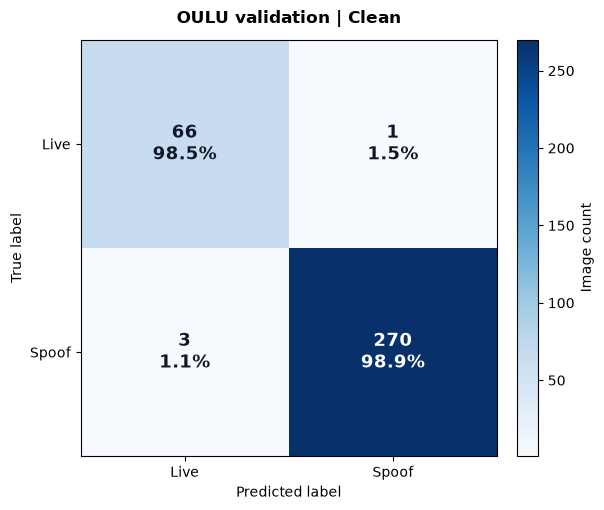

Completed: OULU validation | Clean | 340 images


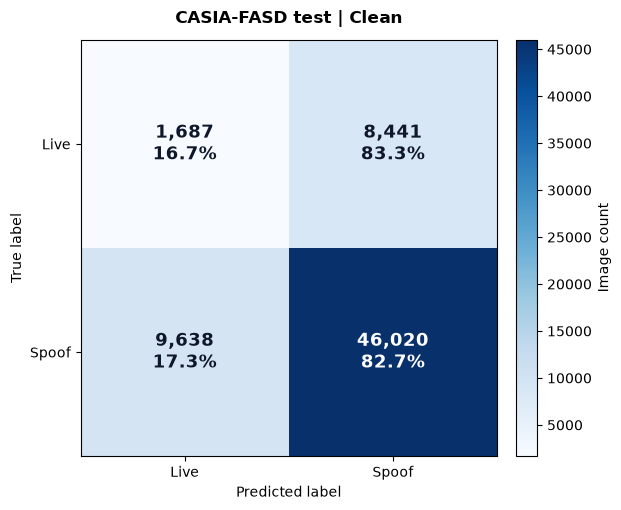

Completed: CASIA-FASD test | Clean | 65,786 images


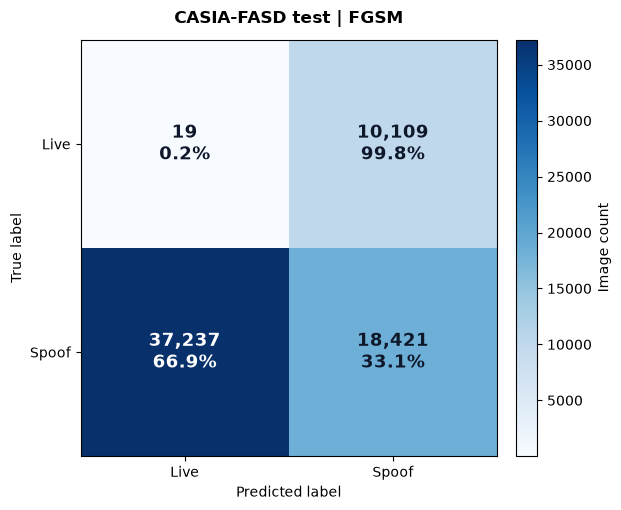

Completed: CASIA-FASD test | FGSM | 65,786 images


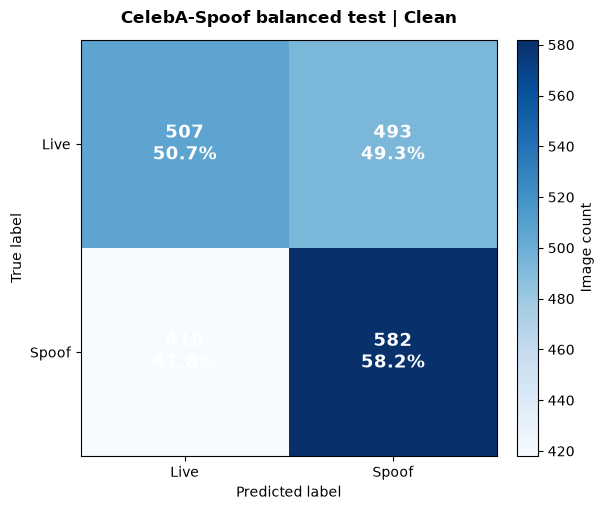

Completed: CelebA-Spoof balanced test | Clean | 2,000 images


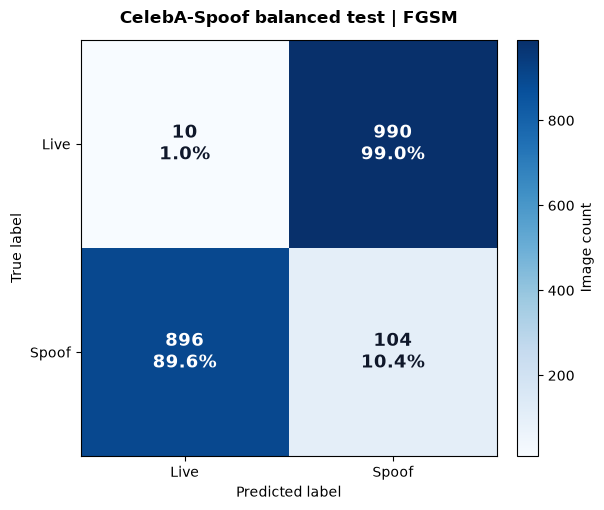

Completed: CelebA-Spoof balanced test | FGSM | 2,000 images
RESULTS
Accuracy is overall correctness; balanced accuracy averages live recall and spoof recall.


NameError: name 'HTML' is not defined

In [10]:
def evaluate(records, dataset_name, condition, use_fgsm=False):
    loader = DataLoader(FaceImageDataset(records), batch_size=BATCH_SIZE,
                        shuffle=False, num_workers=0, pin_memory=pin_memory)
    model.eval()
    y_true, y_pred = [], []
    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=pin_memory)
        labels_device = labels.to(DEVICE, non_blocking=pin_memory)
        if use_fgsm:
            images.requires_grad_(True)
            logits = model(images)
            loss = F.cross_entropy(logits, labels_device)
            gradient = torch.autograd.grad(loss, images)[0]
            eval_images = (images.detach() + FGSM_EPSILON * gradient.sign()).clamp(0.0, 1.0)
            with torch.no_grad():
                predictions = model(eval_images).argmax(dim=1)
        else:
            with torch.no_grad():
                predictions = model(images).argmax(dim=1)
        y_true.extend(labels.tolist())
        y_pred.extend(predictions.cpu().tolist())

    matrix = confusion_matrix(y_true, y_pred, labels=[0, 1])
    live_precision, spoof_precision = precision_score(
        y_true, y_pred, labels=[0, 1], average=None, zero_division=0)
    live_recall, spoof_recall = recall_score(
        y_true, y_pred, labels=[0, 1], average=None, zero_division=0)
    live_f1, spoof_f1 = f1_score(
        y_true, y_pred, labels=[0, 1], average=None, zero_division=0)
    result = {
        'dataset': dataset_name,
        'condition': condition,
        'n_images': len(y_true),
        'accuracy': accuracy_score(y_true, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'live_precision': live_precision,
        'live_recall': live_recall,
        'live_f1': live_f1,
        'spoof_precision': spoof_precision,
        'spoof_recall': spoof_recall,
        'spoof_f1': spoof_f1,
    }

    row_totals = matrix.sum(axis=1, keepdims=True)
    row_percent = np.divide(matrix, row_totals, out=np.zeros_like(matrix, dtype=float),
                            where=row_totals != 0) * 100
    fig, ax = plt.subplots(figsize=(6.2, 5.2))
    image = ax.imshow(matrix, cmap='Blues')
    for row in range(2):
        for column in range(2):
            color = 'white' if matrix[row, column] > matrix.max() * 0.52 else '#0f172a'
            ax.text(column, row,
                    f'{matrix[row, column]:,}\n{row_percent[row, column]:.1f}%',
                    ha='center', va='center', color=color, fontsize=13, fontweight='bold')
    ax.set_xticks([0, 1], labels=['Live', 'Spoof'])
    ax.set_yticks([0, 1], labels=['Live', 'Spoof'])
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('True label')
    ax.set_title(f'{dataset_name} | {condition}', fontweight='bold', pad=12)
    colorbar = fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
    colorbar.set_label('Image count')
    fig.tight_layout()
    safe_name = dataset_name.lower().replace('-', '_').replace(' ', '_')
    fig.savefig(OUTPUT_DIR / f'confusion_{safe_name}_{condition.lower()}_v3.png',
                dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    print(f'Completed: {dataset_name} | {condition} | {len(y_true):,} images')
    return result

results = []
print('EVALUATION STARTED')
print('Class order for all confusion matrices: Live (0), Spoof (1)')
results.append(evaluate(val_records, 'OULU validation', 'Clean', use_fgsm=False))
for dataset_name, records in [('CASIA-FASD test', casia_records),
                             ('CelebA-Spoof balanced test', celeba_records)]:
    results.append(evaluate(records, dataset_name, 'Clean', use_fgsm=False))
    results.append(evaluate(records, dataset_name, 'FGSM', use_fgsm=True))

metrics_path = OUTPUT_DIR / 'metrics_v3.csv'
with metrics_path.open('w', newline='', encoding='utf-8') as metrics_stream:
    writer = csv.DictWriter(metrics_stream, fieldnames=list(results[0].keys()))
    writer.writeheader()
    writer.writerows(results)

print('RESULTS')
print('Accuracy is overall correctness; balanced accuracy averages live recall and spoof recall.')

def html_table(title, headers, rows):
    parts = [f'<h3 style="font-family:Arial,sans-serif;color:#16324f;margin:18px 0 7px">{title}</h3>',
             '<table style="border-collapse:collapse;font-family:Arial,sans-serif;font-size:12px;width:100%">',
             '<thead><tr>']
    parts.extend(f'<th style="background:#16324f;color:white;padding:8px;border:1px solid #cbd5e1;text-align:left">{header}</th>'
                 for header in headers)
    parts.append('</tr></thead><tbody>')
    for row_index, row in enumerate(rows):
        background = '#f1f5f9' if row_index % 2 else '#ffffff'
        parts.append('<tr>')
        parts.extend(f'<td style="background:{background};padding:7px;border:1px solid #cbd5e1">{value}</td>'
                     for value in row)
        parts.append('</tr>')
    parts.append('</tbody></table>')
    return ''.join(parts)

summary_rows = []
class_rows = []
for result in results:
    summary_rows.append([
        result['dataset'], result['condition'], f"{result['n_images']:,}",
        f"{result['accuracy']:.1%}", f"{result['balanced_accuracy']:.1%}",
        f"{result['live_recall']:.1%}", f"{result['spoof_recall']:.1%}"])
    class_rows.append([result['dataset'], result['condition'], 'Live',
                       f"{result['live_precision']:.1%}", f"{result['live_recall']:.1%}",
                       f"{result['live_f1']:.1%}"])
    class_rows.append([result['dataset'], result['condition'], 'Spoof',
                       f"{result['spoof_precision']:.1%}", f"{result['spoof_recall']:.1%}",
                       f"{result['spoof_f1']:.1%}"])

summary_html = html_table('Overall performance',
    ['Dataset', 'Condition', 'Images', 'Accuracy', 'Balanced accuracy', 'Live recall', 'Spoof recall'],
    summary_rows)
class_html = html_table('Metrics by class',
    ['Dataset', 'Condition', 'Class', 'Precision', 'Recall', 'F1 score'],
    class_rows)
display(HTML(summary_html + class_html))
print(f'All metrics and plots saved under: {OUTPUT_DIR}')


## 7. What it means

The confusion matrices show counts and percentages within each true class. The CSV and table report overall accuracy, balanced accuracy, and precision, recall, and F1 for both classes. Spoof recall is especially important: a spoof counted under the predicted Live column is a missed attack.

The OULU subject-holdout result was 98.2% accuracy, but it is optimistic because the same holdout was used to choose the best epoch. On the external tests, clean balanced accuracy was 51.8% on CASIA-FASD and 58.2% on CelebA-Spoof. Under FGSM, accuracy fell to 10.4% and 3.7%, respectively. The training and evaluation pipeline works, but the detector did **not** generalize well across datasets and was **not** robust to FGSM.
